# SDG 11 — Sustainable Cities and Communities
## Analysis of Air Quality in Indian Cities

---

| Item | Detail |
|---|---|
| **Subject** | Data Exploration and Visualization (23CS5PCDEV) |
| **College** | B.M.S. College of Engineering, Bangalore |
| **Dataset** | Indian Cities Air Quality — city_day.csv (CPCB) |
| **SDG Goal** | SDG 11: Sustainable Cities & Communities |
| **Target** | 11.6 — Reduce the environmental impact of cities |

---

## About this Notebook

This notebook covers the **complete pipeline** — from raw data to final visualizations:

1. Load and inspect the **raw** dataset
2. Perform all **data cleaning and preprocessing** steps inline
3. Conduct **statistical analysis** and **EDA**
4. Generate **10 visualizations** answering the research questions

Every visualization is also saved as a PNG to `outputs/graphs/`.

---
# Section 1 — Introduction and Research Questions

## 1.1 SDG 11 Context

**UN Sustainable Development Goal 11** aims to make cities inclusive, safe, resilient, and sustainable by 2030.  
**Target 11.6** specifically calls for reducing the per capita environmental impact of cities, with particular attention to air quality and municipal waste management.

India faces a severe urban air quality crisis. Many Indian cities rank among the most polluted in the world due to rapid urbanization, industrial growth, increasing vehicle traffic, construction dust, and agricultural burning.

The **Air Quality Index (AQI)** is a standardized scale (0–500+) used by India's Central Pollution Control Board (CPCB) to communicate how clean or polluted the air is:

| AQI Range | Category | Health Impact |
|---|---|---|
| 0–50 | Good | Minimal impact |
| 51–100 | Satisfactory | Minor breathing discomfort to sensitive people |
| 101–200 | Moderate | Breathing discomfort to people with lung/heart disease |
| 201–300 | Poor | Breathing discomfort to most people on prolonged exposure |
| 301–400 | Very Poor | Respiratory illness on prolonged exposure |
| 400+ | Severe | Affects healthy people; seriously impacts those with diseases |

## 1.2 Research Questions

This analysis answers the following specific questions:

1. Which Indian city has the **highest average AQI** (most polluted)?
2. Which city has the **lowest average AQI** (least polluted)?
3. How has AQI **changed year by year** from 2015 to 2020?
4. Which **months or seasons** are most polluted?
5. What is the **distribution of AQI categories** across all records?
6. Which **pollutants correlate most strongly** with AQI?
7. What is the **relationship between PM2.5 and PM10**?
8. How do **pollutant levels vary across cities**?

---
# Section 2 — Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings

warnings.filterwarnings('ignore')

# ── Output directory for saving graphs ──
NOTEBOOK_DIR = os.path.abspath('')
PROJECT_ROOT = os.path.dirname(NOTEBOOK_DIR)
GRAPH_DIR    = os.path.join(PROJECT_ROOT, 'outputs', 'graphs')
TABLE_DIR    = os.path.join(PROJECT_ROOT, 'outputs', 'tables')
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# ── Global style settings ──
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({
    'figure.dpi'  : 130,
    'savefig.dpi' : 150,
    'savefig.bbox': 'tight',
})

print('Libraries imported successfully.')
print(f'Graphs will be saved to: {GRAPH_DIR}')

Libraries imported successfully.
Graphs will be saved to: C:\Users\omkar\OneDrive\Desktop\DEV AAT\DEV_AAT_SDG11\outputs\graphs


---
# Section 3 — Data Cleaning and Preprocessing

We start from the **raw** `city_day.csv` and clean it step by step inside this notebook.  
This mirrors the pipeline in `src/dfmodif.py` but runs interactively so every transformation is visible.

**Pipeline overview:**

| Step | Operation |
|---|---|
| 3.1 | Load raw dataset — inspect shape, types, missing values |
| 3.2 | Date conversion, city name cleaning, sorting |
| 3.3 | Deduplication |
| 3.4 | Drop Xylene column (61.3% missing) |
| 3.5 | Missing value imputation — forward fill → backward fill → median |
| 3.6 | Drop rows with missing AQI / AQI_Bucket |
| 3.7 | Feature engineering — Year, Month, PM2.5_Severity |
| 3.8 | Data quality checks |
| 3.9 | Before vs After summary |

## 3.1 — Load Raw Dataset

We load the original unmodified `city_day.csv` and examine its structure before any changes.

In [2]:
RAW_PATH = os.path.join(PROJECT_ROOT, 'dataset', 'raw', 'city_day.csv')

df_raw = pd.read_csv(RAW_PATH)

print(f'Raw shape  : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns')
print(f'Columns    : {df_raw.columns.tolist()}')
print(f'\nData types:')
print(df_raw.dtypes.to_string())
print(f'\nFirst 5 rows:')
display(df_raw.head())

Raw shape  : 29,531 rows × 16 columns
Columns    : ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI', 'AQI_Bucket']

Data types:
City              str
Date              str
PM2.5         float64
PM10          float64
NO            float64
NO2           float64
NOx           float64
NH3           float64
CO            float64
SO2           float64
O3            float64
Benzene       float64
Toluene       float64
Xylene        float64
AQI           float64
AQI_Bucket        str

First 5 rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


Columns with missing values (raw):


,Missing Count,Missing %
Xylene,18109,61.3
PM10,11140,37.7
NH3,10328,35.0
Toluene,8041,27.2
Benzene,5623,19.0
AQI,4681,15.9
AQI_Bucket,4681,15.9
PM2.5,4598,15.6
NOx,4185,14.2
O3,4022,13.6


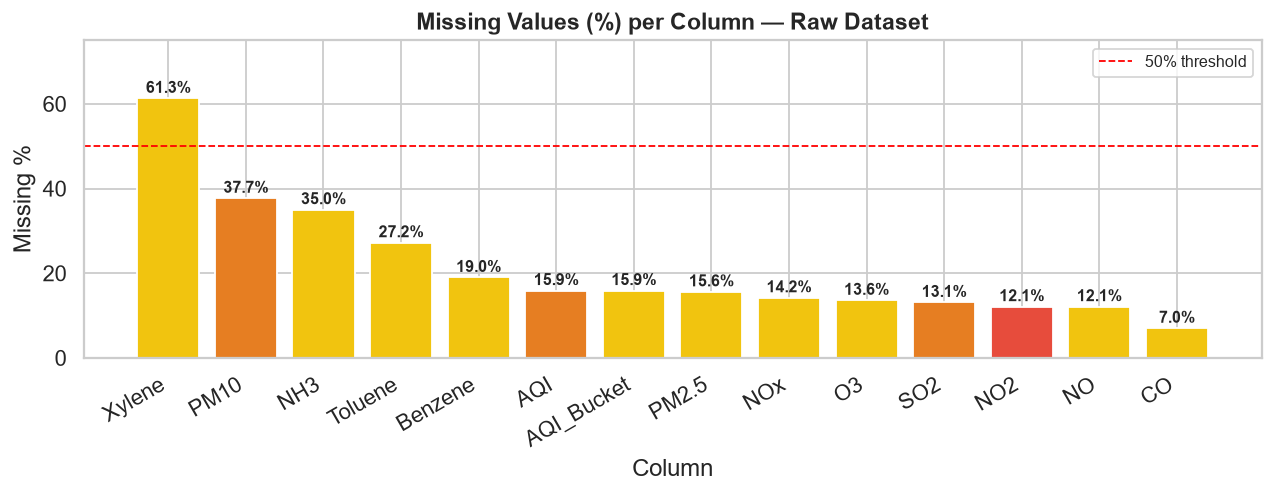

Chart saved → outputs/graphs/00_raw_missing_values.png


In [3]:
# Missing values in the raw dataset
raw_missing     = df_raw.isnull().sum()
raw_missing_pct = (raw_missing / len(df_raw) * 100).round(1)

missing_df = pd.DataFrame({
    'Missing Count': raw_missing,
    'Missing %'    : raw_missing_pct
})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

print('Columns with missing values (raw):')
display(missing_df)

# Bar chart of missing values
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['#e74c3c' if p > 50 else '#e67e22' if p > 25 else '#f1c40f'
          for p in raw_missing_pct[raw_missing_pct > 0]]
ax.bar(missing_df.index, missing_df['Missing %'], color=colors, edgecolor='white')
for i, (col, row) in enumerate(missing_df.iterrows()):
    ax.text(i, row['Missing %'] + 0.5, f"{row['Missing %']}%",
            ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.axhline(50, color='red', linestyle='--', linewidth=1, label='50% threshold')
ax.set_title('Missing Values (%) per Column — Raw Dataset', fontsize=13, fontweight='bold')
ax.set_xlabel('Column')
ax.set_ylabel('Missing %')
ax.set_ylim(0, 75)
ax.legend(fontsize=9)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, '00_raw_missing_values.png'))
plt.show()
print('Chart saved → outputs/graphs/00_raw_missing_values.png')

## 3.2 — Date Conversion, City Name Cleaning and Sorting

Three operations are performed in this step:
- **Date** is converted from a plain text string to a proper `datetime64` object — this is required for time-series operations like sorting and extracting year/month.
- **City names** are stripped of any leading or trailing whitespace using `.str.strip()`. Without this, `'Delhi'` and `' Delhi'` would be counted as two separate cities.
- The dataframe is **sorted** by City then Date. This is essential before the forward-fill imputation in Step 3.5 — filling must happen in chronological order within each city.

In [4]:
df = df_raw.copy()   # work on a copy — never modify the raw dataframe

# Convert Date string → datetime64
df['Date'] = pd.to_datetime(df['Date'])

# Strip whitespace from city names
df['City'] = df['City'].str.strip()

# Sort chronologically within each city (required before imputation)
df = df.sort_values(by=['City', 'Date']).reset_index(drop=True)

print(f"Date dtype after conversion : {df['Date'].dtype}")
print(f"Unique cities               : {df['City'].nunique()}")
print(f"Cities list                 : {sorted(df['City'].unique())}")
print(f"Date range                  : {df['Date'].min().date()} to {df['Date'].max().date()}")

Date dtype after conversion : datetime64[us]
Unique cities               : 26
Cities list                 : ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
Date range                  : 2015-01-01 to 2020-07-01


## 3.3 — Deduplication

We check for exact duplicate rows (all columns identical) and also for logical duplicates — the same city recorded twice on the same date.

In [5]:
before = len(df)
df = df.drop_duplicates()
after = len(df)

city_date_dups = df.duplicated(subset=['City', 'Date']).sum()

print(f'Rows before deduplication        : {before:,}')
print(f'Exact duplicate rows removed     : {before - after}')
print(f'Rows after deduplication         : {after:,}')
print(f'Duplicate City+Date combinations : {city_date_dups}')

Rows before deduplication        : 29,531
Exact duplicate rows removed     : 0
Rows after deduplication         : 29,531
Duplicate City+Date combinations : 0


## 3.4 — Drop Xylene Column

**Xylene has 61.3% missing values** — 18,109 out of 29,531 rows.  
Imputing more than half of a column's values would mean manufacturing data rather than filling genuine sensor gaps. The imputed values would not represent real measurements, introducing severe bias into any analysis that used Xylene.  
The correct decision is to drop it entirely.

In [6]:
xylene_count = df['Xylene'].isnull().sum()
xylene_pct   = xylene_count / len(df) * 100

print(f'Xylene missing values : {xylene_count:,} / {len(df):,} rows ({xylene_pct:.1f}%)')
print('Decision: Drop — imputing 61.3% would manufacture data, not fill gaps.')

df = df.drop(columns=['Xylene'])

print(f'Columns after drop ({len(df.columns)}): {df.columns.tolist()}')

Xylene missing values : 18,109 / 29,531 rows (61.3%)
Decision: Drop — imputing 61.3% would manufacture data, not fill gaps.
Columns after drop (15): ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Bucket']


## 3.5 — Missing Value Imputation for Pollutant Columns

Air quality follows continuous temporal trends — a sensor reading on Monday is a reasonable estimate for Tuesday if the sensor was offline. We exploit this with a three-stage strategy:

1. **Forward fill (`ffill`)** — carry the last known value forward within each city's time series.
2. **Backward fill (`bfill`)** — fill any gaps at the very start of a city's monitoring period.
3. **Global median fallback** — for cities that have no readings at all for a particular pollutant.

> **Limitation:** If a sensor is offline for many consecutive days, all those days receive the same imputed value. These are estimates, not actual sensor readings. They should not be treated as measured data.

In [7]:
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
                  'CO', 'SO2', 'O3', 'Benzene', 'Toluene']

before_impute = df[pollutant_cols].isnull().sum()

for col in pollutant_cols:
    # Forward fill within each city's time series
    df[col] = df.groupby('City')[col].transform(lambda x: x.ffill())
    # Backward fill for gaps at the beginning of a city's monitoring period
    df[col] = df.groupby('City')[col].transform(lambda x: x.bfill())
    # Global median as final fallback
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

after_impute = df[pollutant_cols].isnull().sum()

# Summary table
impute_summary = pd.DataFrame({
    'Missing Before': before_impute,
    'Missing After' : after_impute
})
impute_summary['Filled'] = impute_summary['Missing Before'] - impute_summary['Missing After']

print('Imputation summary:')
display(impute_summary)

print(f'\nTotal NaNs filled: {impute_summary["Filled"].sum():,}')

Imputation summary:


,Missing Before,Missing After,Filled
PM2.5,4598,0,4598
PM10,11140,0,11140
NO,3582,0,3582
NO2,3585,0,3585
NOx,4185,0,4185
NH3,10328,0,10328
CO,2059,0,2059
SO2,3854,0,3854
O3,4022,0,4022
Benzene,5623,0,5623



Total NaNs filled: 61,017


## 3.6 — Remove Rows with Missing AQI / AQI_Bucket

AQI and AQI_Bucket are the **target variables** — the values we want to analyse and explain.  
Rows with no AQI value cannot contribute to the analysis, so they are dropped.  
We do **not** impute AQI because it is a composite index computed from multiple pollutants — imputing it directly would obscure real data quality information.

In [8]:
before_drop = len(df)

df_cleaned = df.dropna(subset=['AQI', 'AQI_Bucket']).reset_index(drop=True)

removed = before_drop - len(df_cleaned)

print(f'Rows before AQI filter  : {before_drop:,}')
print(f'Rows removed (no AQI)   : {removed:,}  ({removed/before_drop*100:.1f}%)')
print(f'Rows retained           : {len(df_cleaned):,}')

Rows before AQI filter  : 29,531
Rows removed (no AQI)   : 4,681  (15.9%)
Rows retained           : 24,850


## 3.7 — Feature Engineering

Three new columns are derived from existing data:

- **`Year`** — extracted from Date using `dt.year`. Enables year-on-year trend analysis.
- **`Month`** — extracted from Date using `dt.month_name()`. Enables seasonal analysis.
- **`PM2.5_Severity`** — continuous PM2.5 value categorised into 6 health tiers using `pd.cut()`. The `include_lowest=True` argument ensures PM2.5 = 0.0 is captured in the 'Good' bin rather than becoming NaN.

In [9]:
df_cleaned = df_cleaned.copy()

# Temporal features
df_cleaned['Year']  = df_cleaned['Date'].dt.year
df_cleaned['Month'] = df_cleaned['Date'].dt.month_name()

# PM2.5 severity binning
pm25_bins   = [0, 30, 60, 90, 120, 250, 1000]
pm25_labels = ['Good', 'Satisfactory', 'Moderately Polluted', 'Poor', 'Very Poor', 'Severe']

df_cleaned['PM2.5_Severity'] = pd.cut(
    df_cleaned['PM2.5'],
    bins=pm25_bins,
    labels=pm25_labels,
    include_lowest=True
)

print('New columns added: Year, Month, PM2.5_Severity')
print(f'\nPM2.5_Severity distribution:')
sev_counts = df_cleaned['PM2.5_Severity'].value_counts().sort_index()
for cat, cnt in sev_counts.items():
    pct = cnt / len(df_cleaned) * 100
    bar = '█' * int(pct / 2)
    print(f'  {str(cat):<22s}: {cnt:5,}  ({pct:.1f}%)  {bar}')

New columns added: Year, Month, PM2.5_Severity

PM2.5_Severity distribution:
  Good                  : 6,585  (26.5%)  █████████████
  Satisfactory          : 8,445  (34.0%)  ████████████████
  Moderately Polluted   : 4,405  (17.7%)  ████████
  Poor                  : 1,945  (7.8%)  ███
  Very Poor             : 2,919  (11.7%)  █████
  Severe                :   551  (2.2%)  █


## 3.8 — Data Quality Checks

After cleaning, we run checks for physically impossible or statistically suspicious values.  
These are flagged but **not automatically removed** — not every statistical outlier is an error.

In [10]:
print('=== DATA QUALITY CHECKS (after cleaning) ===')

# 1. Negative pollutant values (physically impossible)
print('\n1. Negative pollutant values:')
neg_found = False
for col in pollutant_cols:
    neg = (df_cleaned[col] < 0).sum()
    if neg > 0:
        print(f'   WARNING — {col}: {neg} negative values')
        neg_found = True
if not neg_found:
    print('   None found — all pollutant readings are non-negative. ✓')

# 2. AQI > 500 (above standard scale — real but extreme)
aqi_extreme = (df_cleaned['AQI'] > 500).sum()
print(f'\n2. AQI > 500 (extreme readings): {aqi_extreme} records')
print('   Decision: Retained — these are extreme but genuine pollution events.')
if aqi_extreme > 0:
    top_extreme = df_cleaned[df_cleaned['AQI'] > 500].groupby('City').size().sort_values(ascending=False)
    print('   Cities with most extreme readings:')
    for city, cnt in top_extreme.head(5).items():
        print(f'     {city}: {cnt} days')

# 3. PM10 < PM2.5 (suspicious — PM2.5 is a subset of PM10)
pm_suspect = (df_cleaned['PM10'] < df_cleaned['PM2.5']).sum()
print(f'\n3. PM10 < PM2.5 (suspicious): {pm_suspect} records')
print('   Decision: Flagged — may be an imputation artifact where PM10 and PM2.5')
print('   were filled from different reference points. Not removed.')

# 4. Skewness
print('\n4. Skewness of key columns:')
for col in ['PM2.5', 'PM10', 'NO2', 'AQI']:
    sk = df_cleaned[col].skew()
    direction = 'right-skewed (long tail of high values)' if sk > 1 else 'approx normal'
    print(f'   {col:<8}: {sk:5.2f}  — {direction}')

=== DATA QUALITY CHECKS (after cleaning) ===

1. Negative pollutant values:
   None found — all pollutant readings are non-negative. ✓

2. AQI > 500 (extreme readings): 543 records
   Decision: Retained — these are extreme but genuine pollution events.
   Cities with most extreme readings:
     Ahmedabad: 412 days
     Delhi: 48 days
     Patna: 25 days
     Gurugram: 22 days
     Lucknow: 15 days

3. PM10 < PM2.5 (suspicious): 2757 records
   Decision: Flagged — may be an imputation artifact where PM10 and PM2.5
   were filled from different reference points. Not removed.

4. Skewness of key columns:
   PM2.5   :  2.82  — right-skewed (long tail of high values)
   PM10    :  1.96  — right-skewed (long tail of high values)
   NO2     :  2.45  — right-skewed (long tail of high values)
   AQI     :  3.40  — right-skewed (long tail of high values)


## 3.9 — Before vs After Cleaning Summary

A side-by-side comparison of the dataset before and after all preprocessing steps.

In [11]:
summary = pd.DataFrame([
    ['Rows',             f'{df_raw.shape[0]:,}',  f'{df_cleaned.shape[0]:,}'],
    ['Columns',          str(df_raw.shape[1]),    str(df_cleaned.shape[1])],
    ['Duplicate rows',   str(df_raw.duplicated().sum()),  '0'],
    ['Xylene column',    'Present (61.3% missing)', 'Dropped'],
    ['Date column type', 'str (plain text)',       'datetime64'],
    ['Missing pollutants', f'{df_raw[pollutant_cols].isnull().sum().sum():,} NaNs',
                           '0 NaNs (imputed)'],
    ['Missing AQI rows', '4,681',  'Removed'],
    ['PM2.5_Severity',   'Not present', '6-tier category column'],
    ['Year column',      'Not present', 'Derived from Date'],
    ['Month column',     'Not present', 'Derived from Date'],
], columns=['Attribute', 'Before Cleaning', 'After Cleaning'])

display(summary)

print(f'\nFinal shape    : {df_cleaned.shape[0]:,} rows × {df_cleaned.shape[1]} columns')
print(f'Missing values : {df_cleaned.isnull().sum().sum()} (zero across all columns)')
print(f'Unique cities  : {df_cleaned["City"].nunique()}')
print(f'Date range     : {df_cleaned["Date"].min().date()} to {df_cleaned["Date"].max().date()}')
print('\n✓ Dataset is clean and ready for analysis.')

,Attribute,Before Cleaning,After Cleaning
0,Rows,"29,531","24,850"
1,Columns,16,18
2,Duplicate rows,0,0
3,Xylene column,Present (61.3% missing),Dropped
4,Date column type,str (plain text),datetime64
5,Missing pollutants,"61,017 NaNs",0 NaNs (imputed)
6,Missing AQI rows,"4,681",Removed
7,PM2.5_Severity,Not present,6-tier category column
8,Year column,Not present,Derived from Date
9,Month column,Not present,Derived from Date



Final shape    : 24,850 rows × 18 columns
Missing values : 0 (zero across all columns)
Unique cities  : 26
Date range     : 2015-01-01 to 2020-07-01

✓ Dataset is clean and ready for analysis.


---
# Section 4 — Initial Data Exploration

With the data fully cleaned, we confirm its structure and examine basic properties.

In [12]:
# Column names, non-null counts, and data types
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 24850 entries, 0 to 24849
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   City            24850 non-null  str           
 1   Date            24850 non-null  datetime64[us]
 2   PM2.5           24850 non-null  float64       
 3   PM10            24850 non-null  float64       
 4   NO              24850 non-null  float64       
 5   NO2             24850 non-null  float64       
 6   NOx             24850 non-null  float64       
 7   NH3             24850 non-null  float64       
 8   CO              24850 non-null  float64       
 9   SO2             24850 non-null  float64       
 10  O3              24850 non-null  float64       
 11  Benzene         24850 non-null  float64       
 12  Toluene         24850 non-null  float64       
 13  AQI             24850 non-null  float64       
 14  AQI_Bucket      24850 non-null  str           
 15  Year         

In [13]:
# Missing value check — must be zero after preprocessing
missing = df_cleaned.isnull().sum()
if missing.sum() == 0:
    print('✓ No missing values in any column.')
else:
    print('Missing values detected:')
    print(missing[missing > 0])

✓ No missing values in any column.


In [14]:
# Key dataset facts
print(f"Unique cities    : {df_cleaned['City'].nunique()}")
print(f"Cities           : {sorted(df_cleaned['City'].unique())}")
print(f"Date range       : {df_cleaned['Date'].min().date()} to {df_cleaned['Date'].max().date()}")
print(f"Years covered    : {sorted(df_cleaned['Year'].unique())}")
print(f"Total records    : {len(df_cleaned):,}")

print('\nAQI Category Distribution:')
counts = df_cleaned['AQI_Bucket'].value_counts()
for cat in counts.index:
    pct = counts[cat] / len(df_cleaned) * 100
    print(f'  {cat:<15s}: {counts[cat]:5,}  ({pct:.1f}%)')

Unique cities    : 26
Cities           : ['Ahmedabad', 'Aizawl', 'Amaravati', 'Amritsar', 'Bengaluru', 'Bhopal', 'Brajrajnagar', 'Chandigarh', 'Chennai', 'Coimbatore', 'Delhi', 'Ernakulam', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kochi', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Shillong', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
Date range       : 2015-01-01 to 2020-07-01
Years covered    : [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020)]
Total records    : 24,850

AQI Category Distribution:
  Moderate       : 8,829  (35.5%)
  Satisfactory   : 8,224  (33.1%)
  Poor           : 2,781  (11.2%)
  Very Poor      : 2,337  (9.4%)
  Good           : 1,341  (5.4%)
  Severe         : 1,338  (5.4%)


In [15]:
# Categorise columns by data type
numerical_cols   = df_cleaned.select_dtypes(include=['float64', 'int32', 'int64']).columns.tolist()
categorical_cols = df_cleaned.select_dtypes(include=['object', 'category']).columns.tolist()

print(f'Numerical columns   ({len(numerical_cols)}): {numerical_cols}')
print(f'Categorical columns ({len(categorical_cols)}): {categorical_cols}')

Numerical columns   (13): ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'Year']
Categorical columns (4): ['City', 'AQI_Bucket', 'Month', 'PM2.5_Severity']


---
# Section 5 — Statistical Analysis

We calculate descriptive statistics for AQI and all pollutant columns to understand the central tendency, spread, and range of measurements.

In [16]:
# Full statistical summary for numeric columns
key_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
stats = df_cleaned[key_cols].describe().round(2)
display(stats)

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,AQI
count,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00,24850.00
mean,68.88,121.75,17.76,28.67,31.73,26.61,2.32,14.50,35.04,166.46
std,64.84,90.56,22.89,24.63,29.99,27.48,7.02,17.83,22.08,140.70
min,0.04,0.03,0.03,0.01,0.00,0.01,0.00,0.01,0.01,13.00
25%,28.90,58.32,5.63,11.71,13.40,9.03,0.58,5.65,19.28,81.00
50%,48.85,97.15,9.93,21.84,23.64,17.00,0.93,9.19,31.12,118.00
75%,82.22,153.97,20.04,37.94,39.08,38.77,1.47,15.28,45.93,208.00
max,914.94,917.08,390.68,362.21,378.24,352.89,175.81,186.08,257.73,2049.00


In [17]:
# Detailed AQI statistics
aqi = df_cleaned['AQI']
print('AQI — Key Statistics')
print(f'  Mean              : {aqi.mean():.1f}')
print(f'  Median            : {aqi.median():.1f}')
print(f'  Std Deviation     : {aqi.std():.1f}')
print(f'  Min               : {aqi.min():.0f}')
print(f'  Max               : {aqi.max():.0f}')
print(f'  25th Percentile   : {aqi.quantile(0.25):.1f}')
print(f'  75th Percentile   : {aqi.quantile(0.75):.1f}')
print(f'  Skewness          : {aqi.skew():.2f}  (right-skewed = long tail of high values)')
print(f'  Records > 300     : {(aqi > 300).sum():,}  ({(aqi > 300).mean()*100:.1f}%)')
print(f'  Records > 500     : {(aqi > 500).sum():,}  ({(aqi > 500).mean()*100:.1f}%)')

AQI — Key Statistics
  Mean              : 166.5
  Median            : 118.0
  Std Deviation     : 140.7
  Min               : 13
  Max               : 2049
  25th Percentile   : 81.0
  75th Percentile   : 208.0
  Skewness          : 3.40  (right-skewed = long tail of high values)
  Records > 300     : 3,675  (14.8%)
  Records > 500     : 543  (2.2%)


In [18]:
# City-wise AQI statistics
city_stats = df_cleaned.groupby('City')['AQI'].agg(['mean','median','std','min','max']).round(1)
city_stats.columns = ['Mean AQI', 'Median AQI', 'Std Dev', 'Min', 'Max']
city_stats = city_stats.sort_values('Mean AQI', ascending=False)

print('City-wise AQI Statistics (sorted by mean, most polluted first):')
display(city_stats)

city_stats.to_csv(os.path.join(TABLE_DIR, 'city_aqi_statistics.csv'))
print(f'\nSaved to outputs/tables/city_aqi_statistics.csv')

City-wise AQI Statistics (sorted by mean, most polluted first):


,Mean AQI,Median AQI,Std Dev,Min,Max
City,,,,,
Ahmedabad,452.1,384.5,311.7,48.0,2049.0
Delhi,259.5,257.0,119.5,29.0,716.0
Patna,240.8,215.0,122.3,53.0,619.0
Gurugram,225.1,208.0,119.9,38.0,891.0
Lucknow,218.0,198.0,117.0,39.0,707.0
Talcher,172.9,128.5,104.9,13.0,570.0
Jorapokhar,159.3,133.0,84.7,27.0,604.0
Brajrajnagar,150.3,122.0,70.4,22.0,355.0
Kolkata,140.6,94.0,104.5,26.0,475.0



Saved to outputs/tables/city_aqi_statistics.csv


In [19]:
# Year-wise AQI statistics
year_stats = df_cleaned.groupby('Year')['AQI'].agg(['mean','median','std','count']).round(1)
year_stats.columns = ['Mean AQI', 'Median AQI', 'Std Dev', 'Record Count']
print('Year-wise AQI Statistics:')
display(year_stats)

Year-wise AQI Statistics:


,Mean AQI,Median AQI,Std Dev,Record Count
Year,,,,
2015,212.5,175.0,133.1,1827
2016,197.2,149.0,130.5,2573
2017,181.5,129.0,141.4,3234
2018,182.7,124.0,171.5,5724
2019,156.5,109.0,135.8,7071
2020,113.5,93.0,83.5,4421


In [20]:
# Skewness of key pollutants
skew_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
skewness  = df_cleaned[skew_cols].skew().round(2).sort_values(ascending=False)
print('Skewness (positive = right-skewed = long tail of high values):')
for col, sk in skewness.items():
    direction = 'right-skewed' if sk > 1 else ('left-skewed' if sk < -1 else 'approx normal')
    print(f'  {col:<8}: {sk:>6.2f}  — {direction}')

Skewness (positive = right-skewed = long tail of high values):
  CO      :   8.70  — right-skewed
  SO2     :   3.90  — right-skewed
  NO      :   3.63  — right-skewed
  AQI     :   3.40  — right-skewed
  NH3     :   3.28  — right-skewed
  PM2.5   :   2.82  — right-skewed
  NO2     :   2.45  — right-skewed
  PM10    :   1.96  — right-skewed
  O3      :   1.38  — right-skewed


---
# Section 6 — Exploratory Data Analysis

We now investigate each research question systematically using computed data.

In [21]:
# Research Question 1 & 2: Most and least polluted cities
city_avg = df_cleaned.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)

print('Top 5 most polluted cities (highest mean AQI):')
for city, aqi_val in city_avg.head(5).items():
    print(f'  {city:<20s}: {aqi_val}')

print('\nTop 5 least polluted cities (lowest mean AQI):')
for city, aqi_val in city_avg.tail(5).items():
    print(f'  {city:<20s}: {aqi_val}')

Top 5 most polluted cities (highest mean AQI):
  Ahmedabad           : 452.1
  Delhi               : 259.5
  Patna               : 240.8
  Gurugram            : 225.1
  Lucknow             : 218.0

Top 5 least polluted cities (lowest mean AQI):
  Ernakulam           : 92.4
  Thiruvananthapuram  : 75.9
  Coimbatore          : 73.0
  Shillong            : 53.8
  Aizawl              : 34.8


In [22]:
# Research Question 3: Year-wise trend
year_avg = df_cleaned.groupby('Year')['AQI'].mean().round(1)
print('Year-wise mean AQI:')
for yr, val in year_avg.items():
    print(f'  {yr}: {val}')

change = year_avg[2019] - year_avg[2015]
print(f'\nChange from 2015 to 2019 (complete years): {change:+.1f} AQI points')

Year-wise mean AQI:
  2015: 212.5
  2016: 197.2
  2017: 181.5
  2018: 182.7
  2019: 156.5
  2020: 113.5

Change from 2015 to 2019 (complete years): -56.0 AQI points


In [23]:
# Research Question 4: Seasonal patterns
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
month_avg = df_cleaned.groupby('Month')['AQI'].mean().reindex(month_order).round(1)

print('Monthly mean AQI:')
for month, val in month_avg.items():
    bar = '█' * int(val / 10)
    print(f'  {month:<12s}: {val:>6.1f}  {bar}')

print(f'\nHighest pollution month: {month_avg.idxmax()} ({month_avg.max():.1f})')
print(f'Lowest  pollution month: {month_avg.idxmin()} ({month_avg.min():.1f})')

Monthly mean AQI:


  January     :  231.7  ███████████████████████
  February    :  202.9  ████████████████████
  March       :  164.7  ████████████████
  April       :  143.4  ██████████████
  May         :  135.5  █████████████
  June        :  120.2  ████████████
  July        :  111.9  ███████████
  August      :  113.6  ███████████
  September   :  115.2  ███████████
  October     :  188.6  ██████████████████
  November    :  241.7  ████████████████████████
  December    :  227.1  ██████████████████████



Highest pollution month: November (241.7)
Lowest  pollution month: July (111.9)


In [24]:
# Research Question 6: Pollutant-AQI correlations
corr_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']
aqi_corr  = df_cleaned[corr_cols + ['AQI']].corr()['AQI'].drop('AQI').sort_values(ascending=False).round(3)

print('Pearson correlation with AQI (strongest first):')
for col, corr_val in aqi_corr.items():
    strength = 'Strong' if abs(corr_val) >= 0.6 else ('Moderate' if abs(corr_val) >= 0.3 else 'Weak')
    print(f'  {col:<8}: {corr_val:>6.3f}  ({strength})')

Pearson correlation with AQI (strongest first):
  CO      :  0.678  (Strong)
  PM2.5   :  0.635  (Strong)
  NO2     :  0.533  (Moderate)
  PM10    :  0.514  (Moderate)
  SO2     :  0.486  (Moderate)
  NOx     :  0.465  (Moderate)
  NO      :  0.436  (Moderate)
  O3      :  0.198  (Weak)
  NH3     :  0.106  (Weak)


In [25]:
# Research Question 7: PM2.5 vs PM10 relationship
pm_corr = df_cleaned['PM2.5'].corr(df_cleaned['PM10'])
print(f'Pearson correlation between PM2.5 and PM10: {pm_corr:.3f}')
print(f'PM2.5 mean: {df_cleaned["PM2.5"].mean():.1f} µg/m³  |  PM10 mean: {df_cleaned["PM10"].mean():.1f} µg/m³')

Pearson correlation between PM2.5 and PM10: 0.594
PM2.5 mean: 68.9 µg/m³  |  PM10 mean: 121.7 µg/m³


---
# Section 7 — Data Visualization

Ten visualizations are produced below.  
Each plot is saved as a PNG to `outputs/graphs/` and displayed inline.

> Each chart is followed by a short interpretation explaining what the visual reveals.

## Visualization 1 — AQI Distribution (Histogram)

**What it shows:** How AQI values are distributed across all 24,850 city-day records.  
The vertical dashed lines mark the official category boundaries.

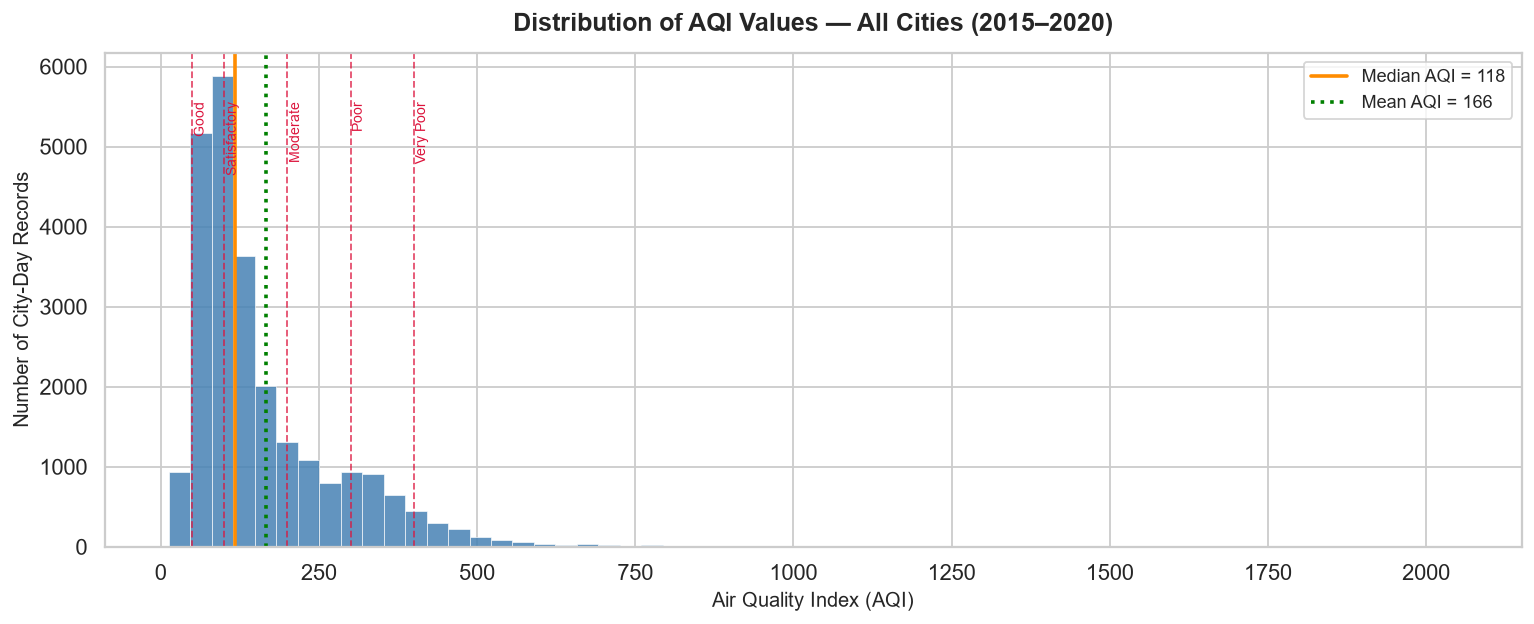

Mean: 166.5 | Median: 118 | Skewness: 3.40
Interpretation: Strongly right-skewed. Most city-days cluster in the 50–250 range,
but a long tail extends past 500, showing extreme events are not rare.


In [26]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(df_cleaned['AQI'], bins=60, color='steelblue', edgecolor='white', linewidth=0.4, alpha=0.85)

boundaries = {50: 'Good', 100: 'Satisfactory', 200: 'Moderate', 300: 'Poor', 400: 'Very Poor'}
for xval, label in boundaries.items():
    ax.axvline(xval, color='crimson', linestyle='--', linewidth=1.0, alpha=0.75)
    ax.text(xval + 2, ax.get_ylim()[1] * 0.90, label,
            fontsize=7.5, color='crimson', rotation=90, va='top')

median_aqi = df_cleaned['AQI'].median()
mean_aqi   = df_cleaned['AQI'].mean()
ax.axvline(median_aqi, color='darkorange', linestyle='-',  linewidth=2, label=f'Median AQI = {median_aqi:.0f}')
ax.axvline(mean_aqi,   color='green',      linestyle=':', linewidth=2, label=f'Mean AQI = {mean_aqi:.0f}')

ax.set_title('Distribution of AQI Values — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Air Quality Index (AQI)', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_distribution.png'))
plt.show()

print(f'Mean: {mean_aqi:.1f} | Median: {median_aqi:.0f} | Skewness: {df_cleaned["AQI"].skew():.2f}')
print('Interpretation: Strongly right-skewed. Most city-days cluster in the 50–250 range,')
print('but a long tail extends past 500, showing extreme events are not rare.')

## Visualization 2 — AQI Category Distribution (Bar Chart)

**What it shows:** Count of city-day records per official CPCB AQI category.

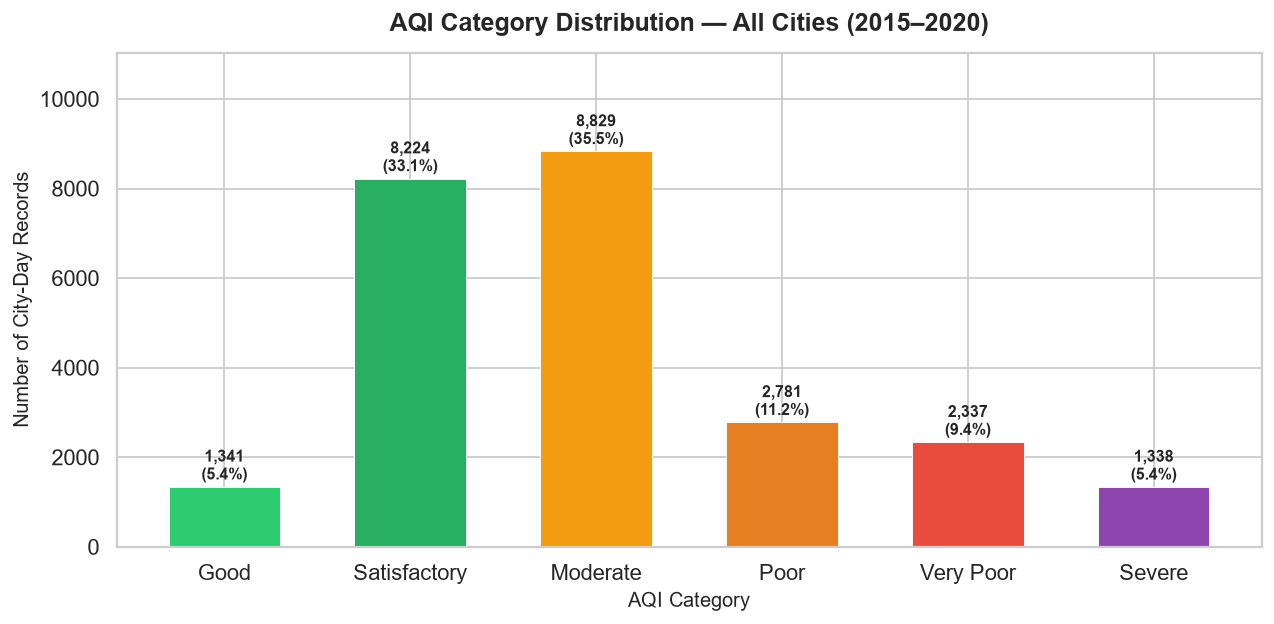

Days with Poor/Very Poor/Severe AQI: 6,456 (26.0%)
Interpretation: Moderate and Satisfactory dominate, but hazardous air is frequent — not rare.


In [27]:
cat_order  = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
cat_colors = ['#2ecc71', '#27ae60', '#f39c12', '#e67e22', '#e74c3c', '#8e44ad']
counts = df_cleaned['AQI_Bucket'].value_counts().reindex(cat_order)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(counts.index, counts.values, color=cat_colors, edgecolor='white', linewidth=0.5, width=0.6)

for bar in bars:
    h   = bar.get_height()
    pct = h / len(df_cleaned) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, h + 60,
            f'{int(h):,}\n({pct:.1f}%)',
            ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_title('AQI Category Distribution — All Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('AQI Category', fontsize=11)
ax.set_ylabel('Number of City-Day Records', fontsize=11)
ax.set_ylim(0, counts.max() * 1.25)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'aqi_category_distribution.png'))
plt.show()

poor_days = counts[['Poor','Very Poor','Severe']].sum()
print(f'Days with Poor/Very Poor/Severe AQI: {poor_days:,} ({poor_days/len(df_cleaned)*100:.1f}%)')
print('Interpretation: Moderate and Satisfactory dominate, but hazardous air is frequent — not rare.')

## Visualization 3 — Top 10 Most Polluted Cities

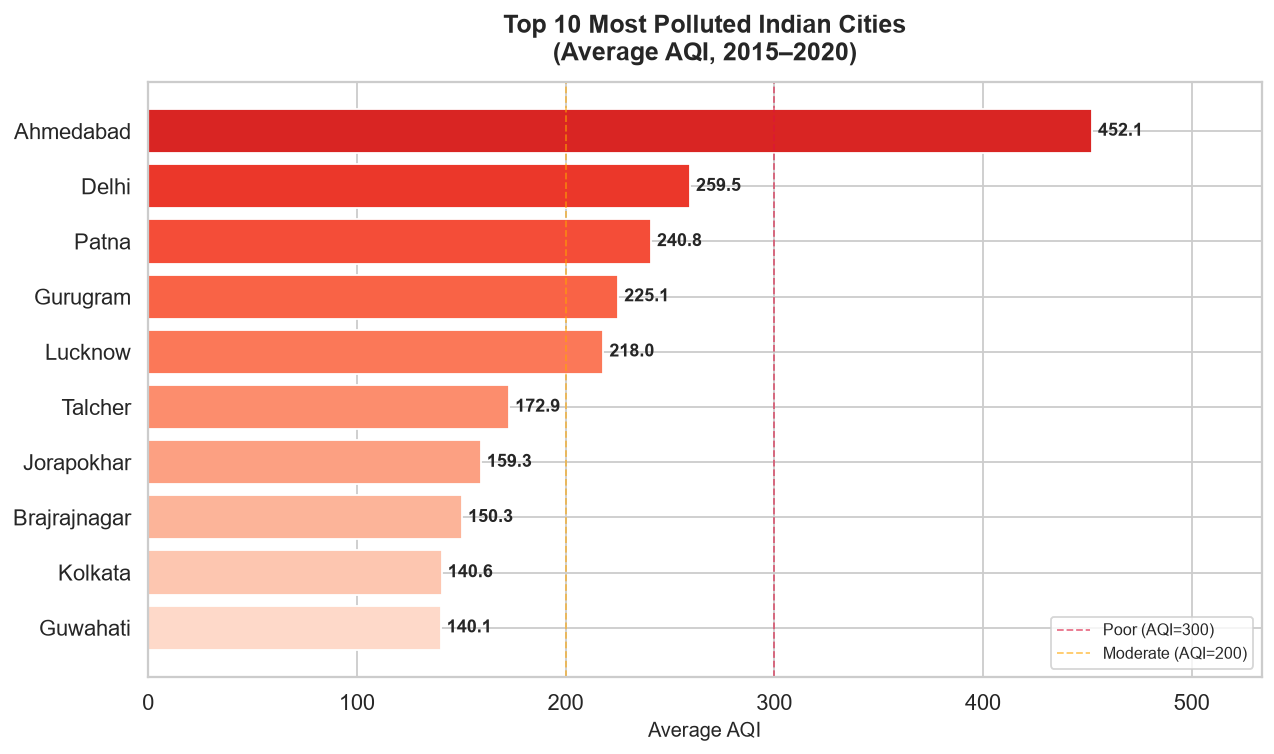

Most polluted: Ahmedabad (avg AQI 452.1)
Interpretation: Most of the top 10 have average AQI in the Poor range.
Residents of these cities face breathing discomfort on a typical day.


In [28]:
city_avg = df_cleaned.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)
top10    = city_avg.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Reds_r(np.linspace(0.3, 0.85, len(top10)))
bars   = ax.barh(top10.index[::-1], top10.values[::-1], color=colors[::-1], edgecolor='white')

for bar, val in zip(bars, top10.values[::-1]):
    ax.text(bar.get_width() + 3, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Top 10 Most Polluted Indian Cities\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average AQI', fontsize=11)
ax.set_xlim(0, top10.max() * 1.18)
ax.axvline(300, color='crimson', linestyle='--', linewidth=1, alpha=0.6, label='Poor (AQI=300)')
ax.axvline(200, color='orange',  linestyle='--', linewidth=1, alpha=0.6, label='Moderate (AQI=200)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'top_polluted_cities.png'))
plt.show()

print(f'Most polluted: {city_avg.index[0]} (avg AQI {city_avg.iloc[0]})')
print('Interpretation: Most of the top 10 have average AQI in the Poor range.')
print('Residents of these cities face breathing discomfort on a typical day.')

## Visualization 4 — Bottom 10 Least Polluted Cities

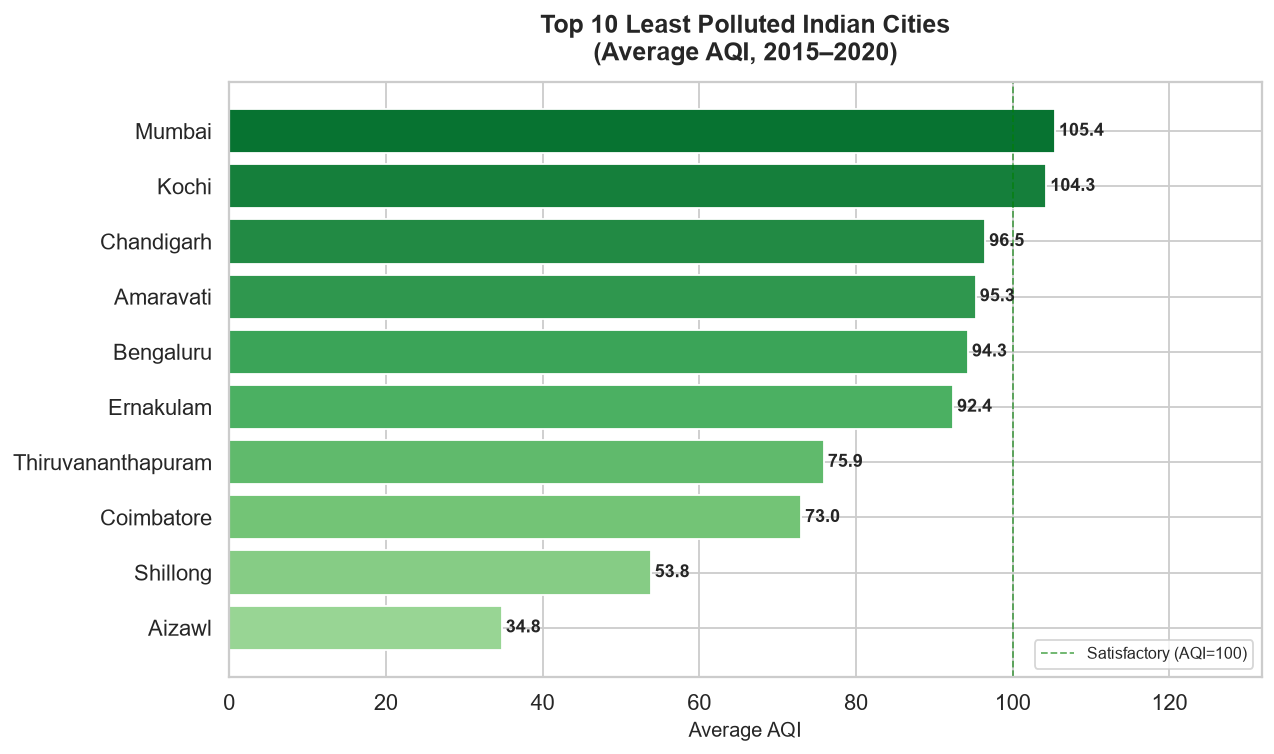

Least polluted: Aizawl (avg AQI 34.8)
Interpretation: Cleanest cities are in northeast India and coastal south India.
Aizawl and Shillong benefit from minimal industry, high rainfall and forest cover.


In [29]:
bot10 = city_avg.tail(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Greens(np.linspace(0.4, 0.85, len(bot10)))
bars   = ax.barh(bot10.index, bot10.values, color=colors, edgecolor='white')

for bar, val in zip(bars, bot10.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val}', va='center', fontsize=10, fontweight='bold')

ax.set_title('Top 10 Least Polluted Indian Cities\n(Average AQI, 2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Average AQI', fontsize=11)
ax.set_xlim(0, bot10.max() * 1.25)
ax.axvline(100, color='green', linestyle='--', linewidth=1, alpha=0.6, label='Satisfactory (AQI=100)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'least_polluted_cities.png'))
plt.show()

print(f'Least polluted: {city_avg.index[-1]} (avg AQI {city_avg.iloc[-1]})')
print('Interpretation: Cleanest cities are in northeast India and coastal south India.')
print('Aizawl and Shillong benefit from minimal industry, high rainfall and forest cover.')

## Visualization 5 — Year-wise Average AQI Trend

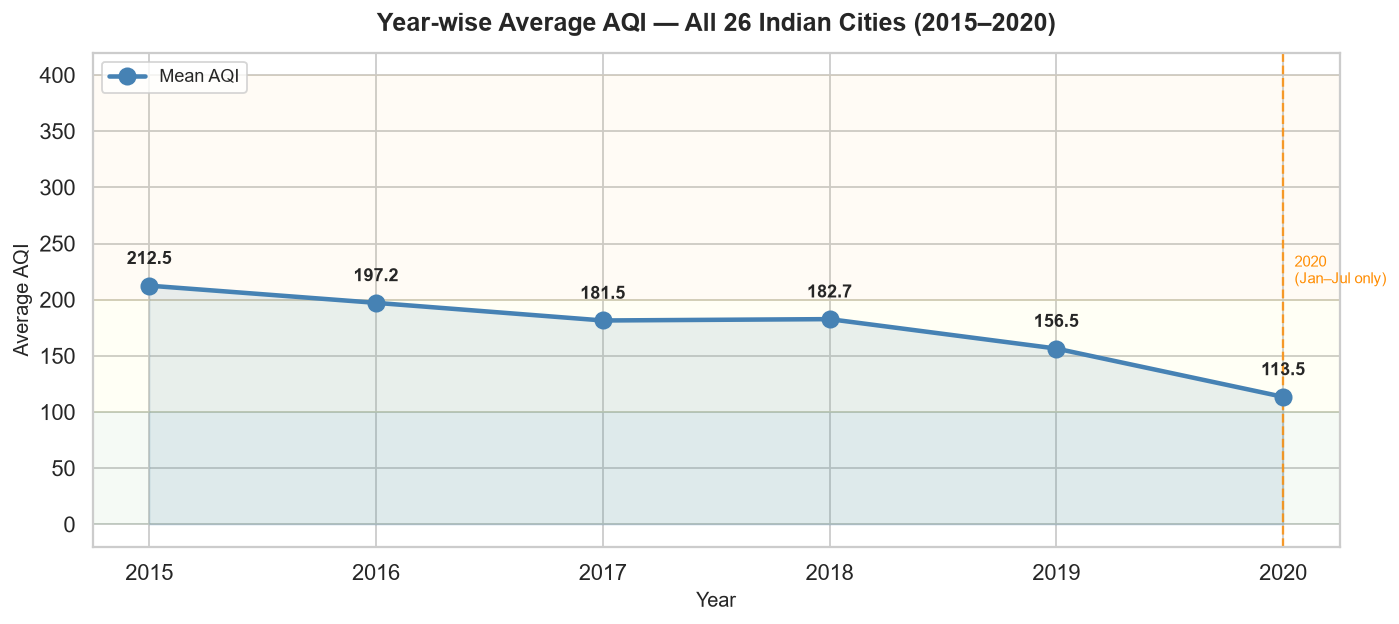

Interpretation: General downward trend from 2015 to 2020.
2020 must be read with caution — partial year + COVID-19 lockdown effect.


In [30]:
year_avg = df_cleaned.groupby('Year')['AQI'].mean().round(1)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(year_avg.index, year_avg.values, marker='o', color='steelblue',
        linewidth=2.5, markersize=9, zorder=3, label='Mean AQI')
ax.fill_between(year_avg.index, year_avg.values, alpha=0.12, color='steelblue')

for yr, val in year_avg.items():
    ax.annotate(f'{val}', (yr, val), textcoords='offset points',
                xytext=(0, 12), ha='center', fontsize=10, fontweight='bold')

ax.axvline(2020, color='darkorange', linestyle='--', linewidth=1.3, alpha=0.8)
ax.text(2020.05, year_avg.max() * 1.01, '2020\n(Jan–Jul only)', fontsize=8.5, color='darkorange')
ax.axhspan(0, 100, alpha=0.04, color='green')
ax.axhspan(100, 200, alpha=0.04, color='yellow')
ax.axhspan(200, 400, alpha=0.04, color='orange')

ax.set_title('Year-wise Average AQI — All 26 Indian Cities (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Average AQI', fontsize=11)
ax.set_xticks(year_avg.index)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'yearly_aqi_trend.png'))
plt.show()

print('Interpretation: General downward trend from 2015 to 2020.')
print('2020 must be read with caution — partial year + COVID-19 lockdown effect.')

## Visualization 6 — Monthly Average AQI (Seasonal Pattern)

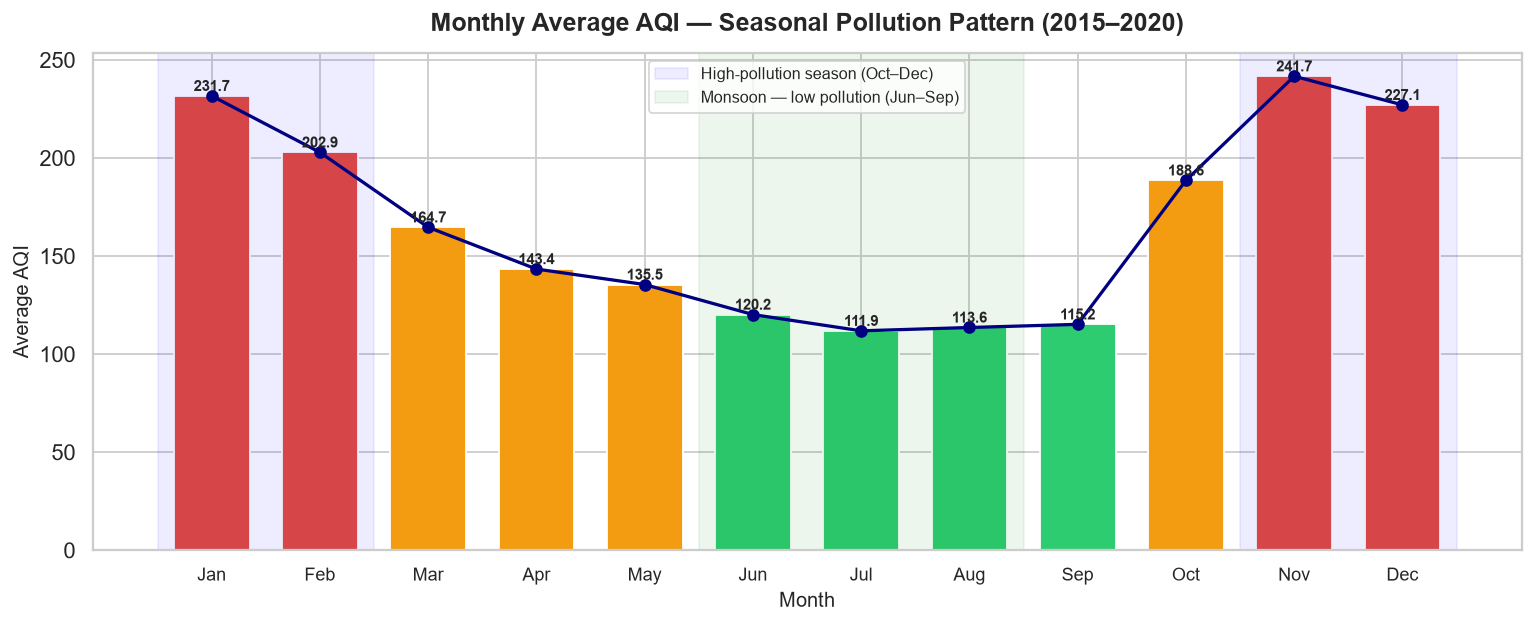

Peak month: November (241.7)
Lowest month: July (111.9)
Interpretation: Winter peaks due to inversions and crop burning; monsoon dips due to rainfall.


In [31]:
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']
month_short = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_avg   = df_cleaned.groupby('Month')['AQI'].mean().reindex(month_order).round(1)

bar_colors = ['#e74c3c' if v > 200 else '#f39c12' if v > 130 else '#2ecc71'
              for v in month_avg.values]

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(1, 13), month_avg.values, color=bar_colors, edgecolor='white', width=0.7)
ax.plot(range(1, 13), month_avg.values, marker='o', color='navy', linewidth=1.8, markersize=6, zorder=3)

for i, val in enumerate(month_avg.values):
    ax.text(i + 1, val + 2.5, f'{val}', ha='center', fontsize=8.5, fontweight='bold')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_short, fontsize=10)
ax.set_title('Monthly Average AQI — Seasonal Pollution Pattern (2015–2020)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Month', fontsize=11)
ax.set_ylabel('Average AQI', fontsize=11)
ax.axvspan(10.5, 12.5, alpha=0.07, color='blue', label='High-pollution season (Oct–Dec)')
ax.axvspan(0.5,  2.5,  alpha=0.07, color='blue')
ax.axvspan(5.5,  8.5,  alpha=0.07, color='green', label='Monsoon — low pollution (Jun–Sep)')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'monthly_aqi_trend.png'))
plt.show()

print(f'Peak month: {month_avg.idxmax()} ({month_avg.max():.1f})')
print(f'Lowest month: {month_avg.idxmin()} ({month_avg.min():.1f})')
print('Interpretation: Winter peaks due to inversions and crop burning; monsoon dips due to rainfall.')

## Visualization 7 — Pollutant Correlation Heatmap

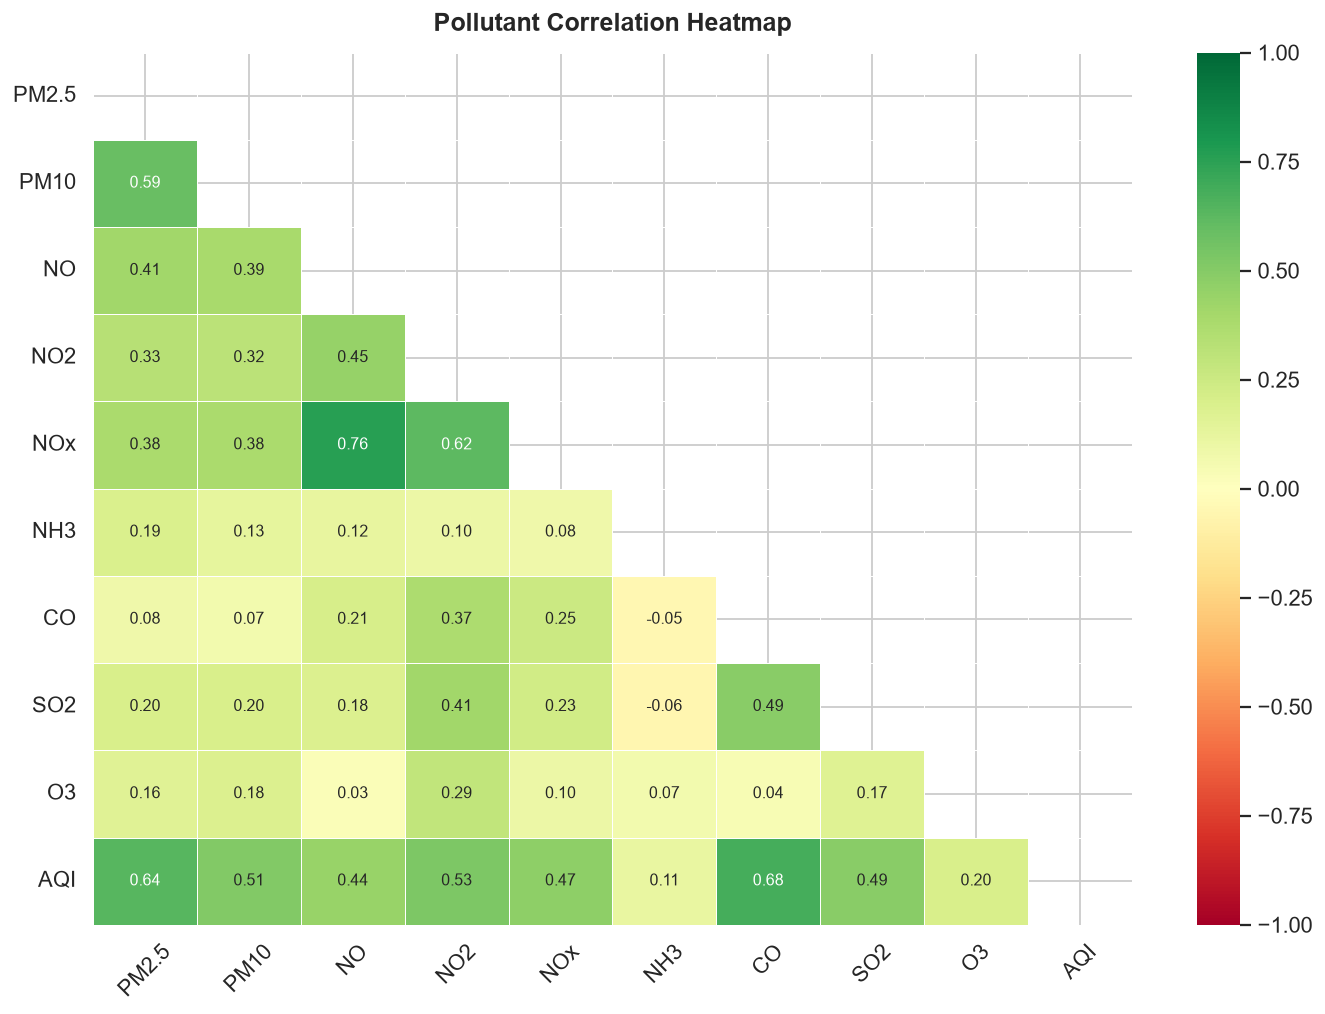

Correlation with AQI (strongest first):
  CO      : 0.680
  PM2.5   : 0.640
  NO2     : 0.530
  PM10    : 0.510
  SO2     : 0.490
  NOx     : 0.470
  NO      : 0.440
  O3      : 0.200
  NH3     : 0.110
Interpretation: PM2.5 and CO are the strongest drivers of AQI.


In [32]:
corr_cols   = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'AQI']
corr_matrix = df_cleaned[corr_cols].corr().round(2)
mask        = np.triu(np.ones_like(corr_matrix, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, linewidths=0.5, ax=ax, annot_kws={'size': 9})
ax.set_title('Pollutant Correlation Heatmap', fontsize=14, fontweight='bold', pad=12)
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_correlation_heatmap.png'))
plt.show()

aqi_corr = corr_matrix['AQI'].drop('AQI').sort_values(ascending=False)
print('Correlation with AQI (strongest first):')
for col, val in aqi_corr.items():
    print(f'  {col:<8}: {val:.3f}')
print('Interpretation: PM2.5 and CO are the strongest drivers of AQI.')

## Visualization 8 — PM2.5 vs PM10 Scatter Plot

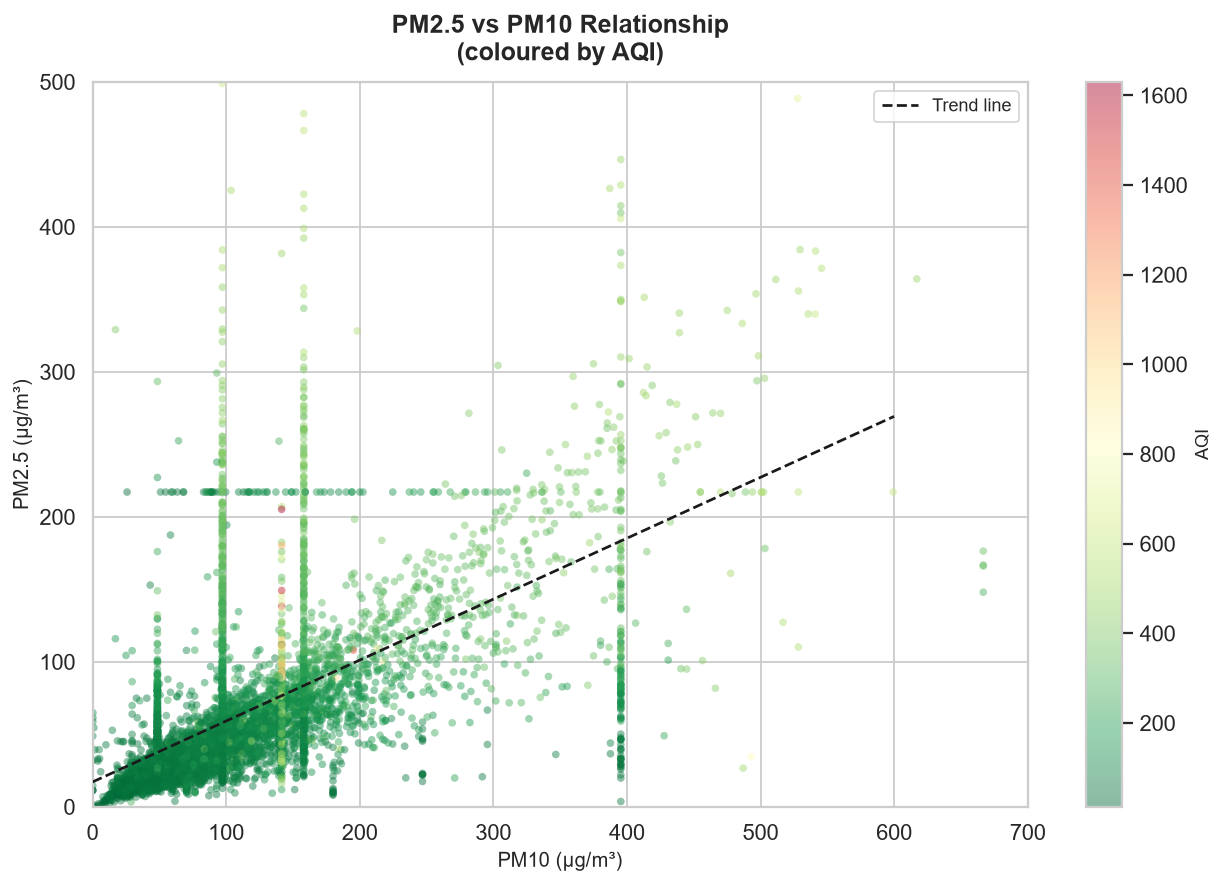

Pearson r PM2.5 vs PM10: 0.594
Interpretation: Strong positive correlation. Red points (high AQI) cluster top-right.


In [33]:
sample = df_cleaned.sample(n=min(6000, len(df_cleaned)), random_state=42)

fig, ax = plt.subplots(figsize=(10, 7))
sc = ax.scatter(sample['PM10'], sample['PM2.5'],
                c=sample['AQI'], cmap='RdYlGn_r', alpha=0.45, s=18, edgecolors='none')

x_clip = sample['PM10'].clip(upper=600)
y_clip = sample['PM2.5'].clip(upper=400)
z      = np.polyfit(x_clip, y_clip, 1)
p      = np.poly1d(z)
x_line = np.linspace(0, 600, 300)
ax.plot(x_line, p(x_line), 'k--', linewidth=1.5, label='Trend line', zorder=4)

cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('AQI', fontsize=10)
ax.set_xlim(0, 700)
ax.set_ylim(0, 500)
ax.set_title('PM2.5 vs PM10 Relationship\n(coloured by AQI)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('PM10 (µg/m³)', fontsize=11)
ax.set_ylabel('PM2.5 (µg/m³)', fontsize=11)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pm25_pm10_scatter.png'))
plt.show()

corr = df_cleaned['PM2.5'].corr(df_cleaned['PM10'])
print(f'Pearson r PM2.5 vs PM10: {corr:.3f}')
print('Interpretation: Strong positive correlation. Red points (high AQI) cluster top-right.')

## Visualization 9 — Pollutant Distribution Box Plots

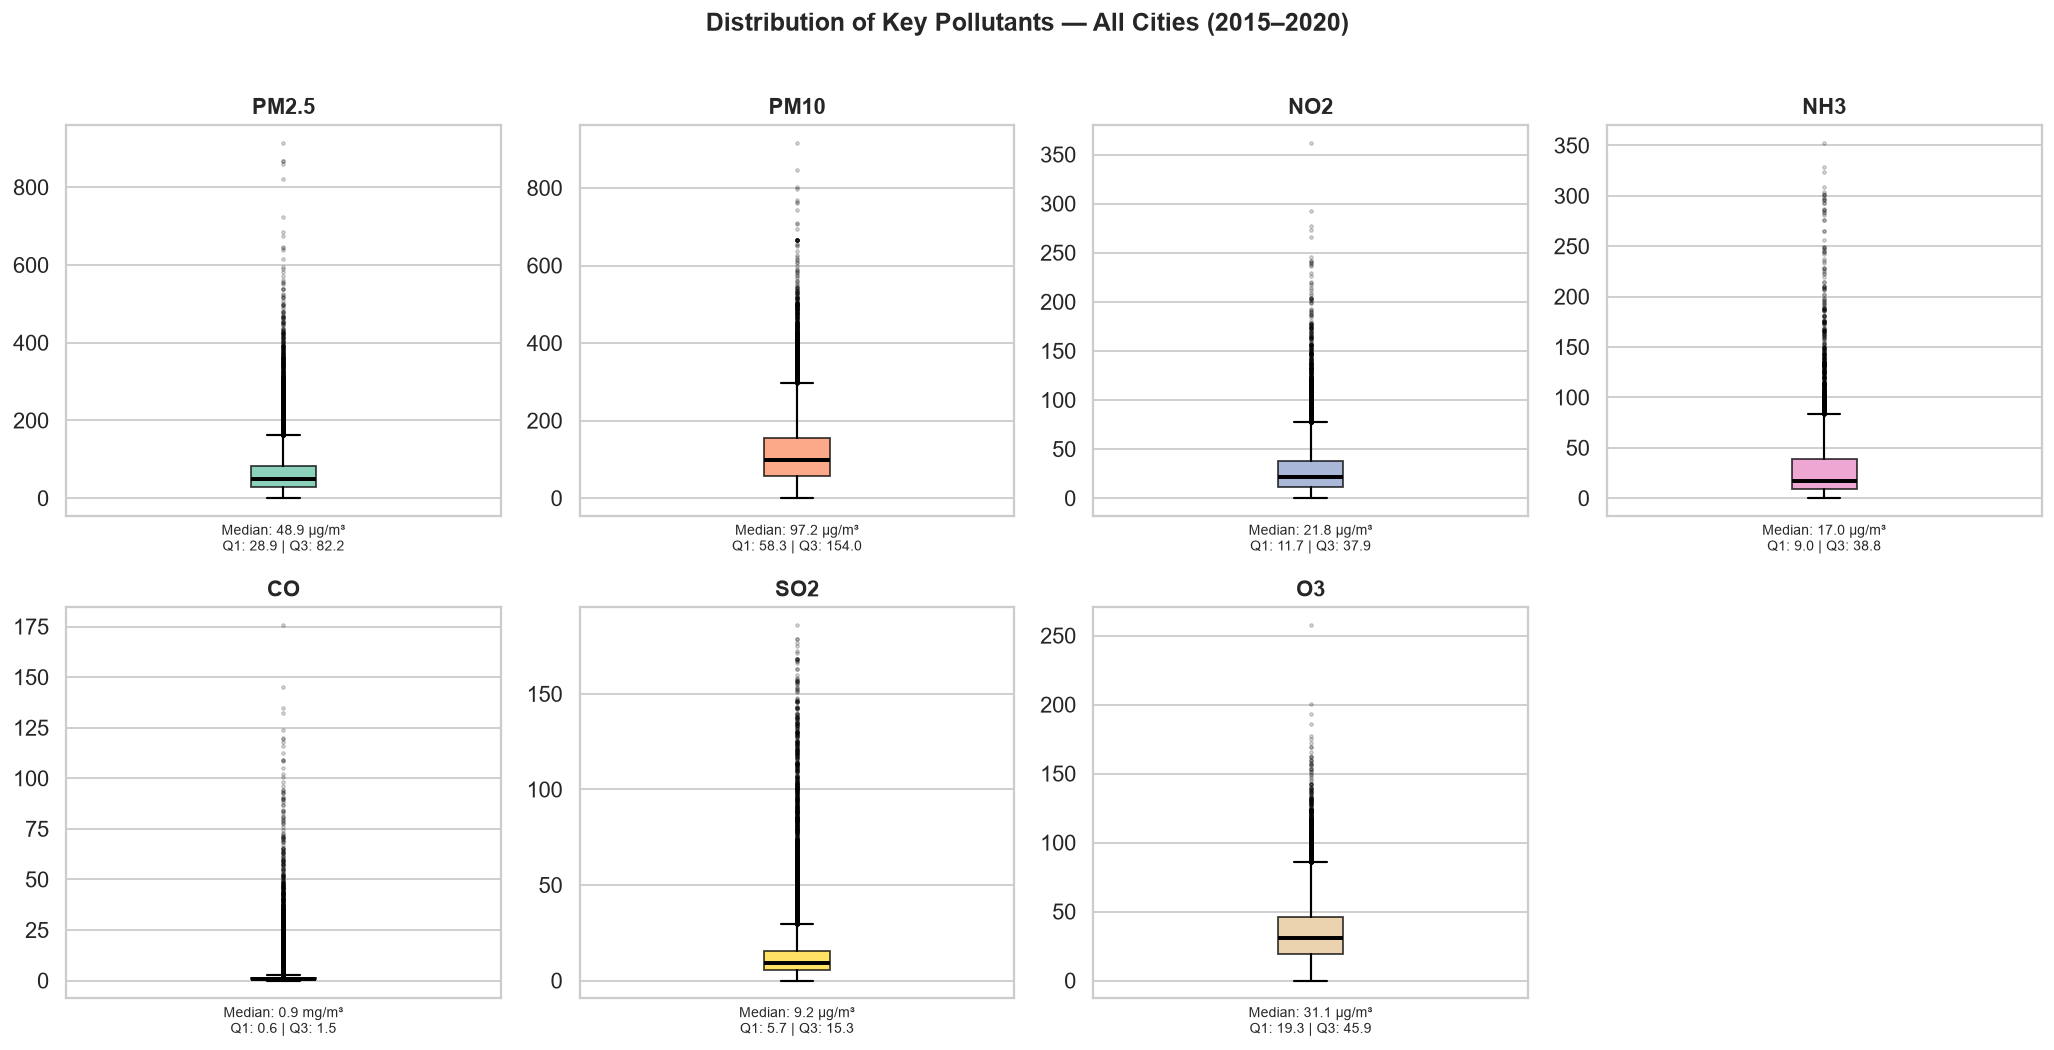

Interpretation: All pollutants are right-skewed with many high-value outliers.
PM10 has the highest median and widest spread.


In [34]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'NH3', 'CO', 'SO2', 'O3']
palette    = sns.color_palette('Set2', len(pollutants))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, (pol, color) in enumerate(zip(pollutants, palette)):
    axes[i].boxplot(
        df_cleaned[pol].dropna(),
        patch_artist=True,
        boxprops    =dict(facecolor=color, alpha=0.75),
        medianprops =dict(color='black', linewidth=2.2),
        whiskerprops=dict(linewidth=1.2),
        capprops    =dict(linewidth=1.2),
        flierprops  =dict(marker='o', markersize=1.5, alpha=0.25, color=color)
    )
    median_val = df_cleaned[pol].median()
    q1  = df_cleaned[pol].quantile(0.25)
    q3  = df_cleaned[pol].quantile(0.75)
    unit = 'mg/m³' if pol == 'CO' else 'µg/m³'
    axes[i].set_title(pol, fontweight='bold', fontsize=12)
    axes[i].set_xlabel(f'Median: {median_val:.1f} {unit}\nQ1: {q1:.1f} | Q3: {q3:.1f}', fontsize=8)
    axes[i].set_xticks([])

axes[-1].set_visible(False)
fig.suptitle('Distribution of Key Pollutants — All Cities (2015–2020)', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'pollutant_boxplots.png'))
plt.show()

print('Interpretation: All pollutants are right-skewed with many high-value outliers.')
print('PM10 has the highest median and widest spread.')

## Visualization 10 — City-wise Pollutant Comparison (Grouped Bar Chart)

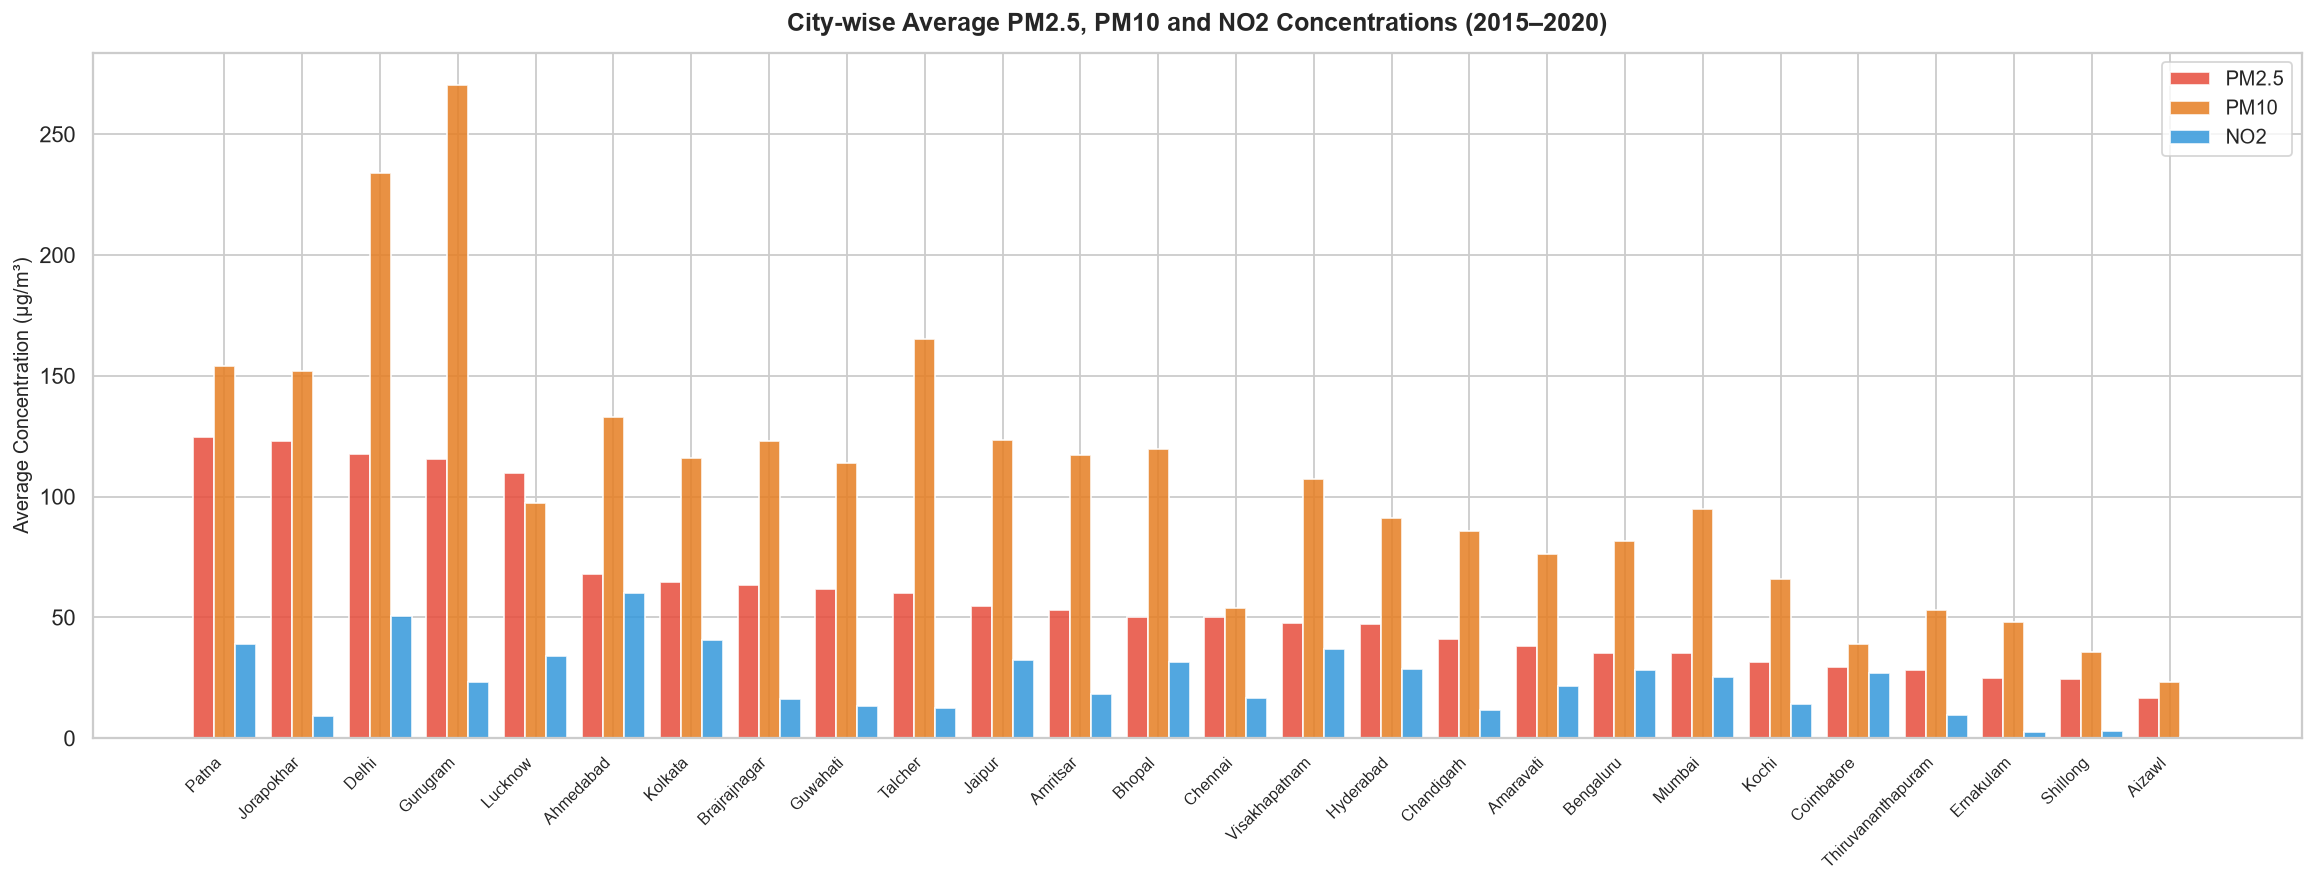

Interpretation: Delhi leads in PM2.5; Gurugram has the highest PM10.
NO2 is highest in Ahmedabad and Delhi — reflecting dense vehicle traffic.


In [35]:
city_poll = df_cleaned.groupby('City')[['PM2.5', 'PM10', 'NO2']].mean().sort_values('PM2.5', ascending=False).round(1)
x     = np.arange(len(city_poll))
width = 0.27

fig, ax = plt.subplots(figsize=(18, 7))
ax.bar(x - width, city_poll['PM2.5'], width, label='PM2.5', color='#e74c3c', alpha=0.85, edgecolor='white')
ax.bar(x,          city_poll['PM10'],  width, label='PM10',  color='#e67e22', alpha=0.85, edgecolor='white')
ax.bar(x + width, city_poll['NO2'],   width, label='NO2',   color='#3498db', alpha=0.85, edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(city_poll.index, rotation=45, ha='right', fontsize=9)
ax.set_title('City-wise Average PM2.5, PM10 and NO2 Concentrations (2015–2020)',
             fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Average Concentration (µg/m³)', fontsize=11)
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(GRAPH_DIR, 'city_pollutant_comparison.png'))
plt.show()

city_poll.to_csv(os.path.join(TABLE_DIR, 'city_pollutant_averages.csv'))
print('Interpretation: Delhi leads in PM2.5; Gurugram has the highest PM10.')
print('NO2 is highest in Ahmedabad and Delhi — reflecting dense vehicle traffic.')

---
# Section 8 — Findings and Observations

In [36]:
city_avg   = df_cleaned.groupby('City')['AQI'].mean().sort_values(ascending=False)
year_avg   = df_cleaned.groupby('Year')['AQI'].mean()
month_avg  = df_cleaned.groupby('Month')['AQI'].mean().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December'])
cat_counts = df_cleaned['AQI_Bucket'].value_counts()
pm_corr    = df_cleaned[['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','AQI']].corr()['AQI'].drop('AQI')

print('=' * 65)
print('COMPUTED FINDINGS FROM THE ANALYSIS')
print('=' * 65)

print(f'\n1. MOST POLLUTED CITY   : {city_avg.index[0]} (avg AQI {city_avg.iloc[0]:.1f})')
print(f'   LEAST POLLUTED CITY  : {city_avg.index[-1]} (avg AQI {city_avg.iloc[-1]:.1f})')
print(f'   AQI gap (max - min)  : {city_avg.iloc[0] - city_avg.iloc[-1]:.1f} units')

print(f'\n2. AQI TREND 2015→2019  : {year_avg[2015]:.1f} → {year_avg[2019]:.1f} (complete years only)')
direction = 'Improvement' if year_avg[2015] > year_avg[2019] else 'Worsening'
print(f'   Direction            : {direction}')

print(f'\n3. PEAK POLLUTION MONTH : {month_avg.idxmax()} (avg AQI {month_avg.max():.1f})')
print(f'   LOWEST MONTH         : {month_avg.idxmin()} (avg AQI {month_avg.min():.1f})')

print(f'\n4. AQI CATEGORY BREAKDOWN:')
for cat in ['Good','Satisfactory','Moderate','Poor','Very Poor','Severe']:
    if cat in cat_counts.index:
        pct = cat_counts[cat] / len(df_cleaned) * 100
        print(f'   {cat:<15s}: {cat_counts[cat]:5,} days ({pct:.1f}%)')

print(f'\n5. STRONGEST POLLUTANT CORRELATIONS WITH AQI:')
for col, val in pm_corr.abs().sort_values(ascending=False).head(3).items():
    print(f'   {col:<8}: r = {pm_corr[col]:.3f}')

print(f'\n6. PM2.5 vs PM10 CORRELATION: r = {df_cleaned["PM2.5"].corr(df_cleaned["PM10"]):.3f}')

poor_pct = (df_cleaned['AQI'] > 200).sum() / len(df_cleaned) * 100
print(f'\n7. RECORDS WITH AQI > 200: {(df_cleaned["AQI"]>200).sum():,} ({poor_pct:.1f}% of all city-days)')

COMPUTED FINDINGS FROM THE ANALYSIS

1. MOST POLLUTED CITY   : Ahmedabad (avg AQI 452.1)
   LEAST POLLUTED CITY  : Aizawl (avg AQI 34.8)
   AQI gap (max - min)  : 417.4 units

2. AQI TREND 2015→2019  : 212.5 → 156.5 (complete years only)
   Direction            : Improvement

3. PEAK POLLUTION MONTH : November (avg AQI 241.7)
   LOWEST MONTH         : July (avg AQI 111.9)

4. AQI CATEGORY BREAKDOWN:
   Good           : 1,341 days (5.4%)
   Satisfactory   : 8,224 days (33.1%)
   Moderate       : 8,829 days (35.5%)
   Poor           : 2,781 days (11.2%)
   Very Poor      : 2,337 days (9.4%)
   Severe         : 1,338 days (5.4%)

5. STRONGEST POLLUTANT CORRELATIONS WITH AQI:
   CO      : r = 0.678
   PM2.5   : r = 0.635
   NO2     : r = 0.533

6. PM2.5 vs PM10 CORRELATION: r = 0.594

7. RECORDS WITH AQI > 200: 6,456 (26.0% of all city-days)


---
# Section 9 — Limitations

**1. Missing data imputation**  
Forward fill and backward fill carry the last known value forward across consecutive missing days. If a station was offline for weeks, all those days receive the same imputed value — not a real measurement.

**2. Incomplete 2020 data**  
The dataset covers only January–July 2020. The apparent drop in AQI for 2020 is not comparable with full-year data. Part of the improvement is likely the COVID-19 lockdown reducing vehicle traffic and industrial activity.

**3. Single monitoring station per city**  
Each city is represented by one station. Large cities like Delhi have highly variable pollution across different zones.

**4. Only 26 cities**  
India has hundreds of cities. Results cannot be extended to represent all of urban India.

**5. Correlation does not imply causation**  
The heatmap shows statistical associations. Temperature, wind, rainfall, and local industry all influence pollution simultaneously.

**6. PM10 < PM2.5 anomaly**  
2,757 records have PM10 lower than PM2.5, which is physically impossible. These likely result from imputation placing PM10 and PM2.5 at different values.

---
# Section 10 — Conclusion

This analysis of 24,850 city-day records from 26 Indian cities (2015–2020) confirms a persistent and unequal air quality crisis in urban India.

**Key conclusions:**

- **Particulate matter is the dominant problem.** PM2.5 and CO have the strongest correlations with AQI and are the primary drivers of the Air Quality Index score across Indian cities.

- **Inequality in air quality is extreme.** The most polluted city (Ahmedabad, avg AQI 452) is roughly 13× worse than the least polluted (Aizawl, avg AQI 35).

- **Winter is the most dangerous season.** November, December, and January consistently show the highest average AQI due to temperature inversions, agricultural burning, and reduced wind.

- **There is a gradual improvement trend.** From 2015 to 2019, average AQI fell — reflecting stricter emission standards and cleaner fuel policies.

- **Most days still exceed safe levels.** Only 5.4% of city-day records fall in the 'Good' category. The majority of urban Indians face Moderate to Poor air quality on a typical day.

**Relevance to SDG 11:**  
These findings directly support SDG 11 Target 11.6. Targeted interventions — emission standards, agricultural waste management, industrial controls, and urban green cover — are needed in specific cities and seasons. Data-driven identification of problem months and cities is essential for effective policy.

---
*Analysis completed using Python, pandas, matplotlib, and seaborn.*